In [1]:
# ----------------------------------------------------------------------
# 0. IMPORTS
# ----------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)

In [2]:
# ----------------------------------------------------------------------
# 1. LOAD + INSPECT
# ----------------------------------------------------------------------

df = pd.read_csv(r"C:\Users\Yadu krishna.M\Downloads\archive (2)\heart.csv")
print(df.shape)
print(df.head())
print(df.info())
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass balance (1 = heart disease):\n", df["HeartDisease"].value_counts())

(918, 12)
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age     

In [4]:
# ----------------------------------------------------------------------
# 2. PREPARE DATA
# ----------------------------------------------------------------------

df = pd.get_dummies(df, drop_first=True, dtype=int)

X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [5]:
# ----------------------------------------------------------------------
# 3. TREE 1: NO LIMITS (grows until every leaf is pure -> overfits)
# ----------------------------------------------------------------------

full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, y_train)

print("\n=== UNRESTRICTED TREE ===")
print("Depth        :", full_tree.get_depth())
print("Leaves       :", full_tree.get_n_leaves())
print("Train acc    :", round(full_tree.score(X_train, y_train), 4))
print("Test acc     :", round(full_tree.score(X_test, y_test), 4))


=== UNRESTRICTED TREE ===
Depth        : 14
Leaves       : 119
Train acc    : 1.0
Test acc     : 0.7826


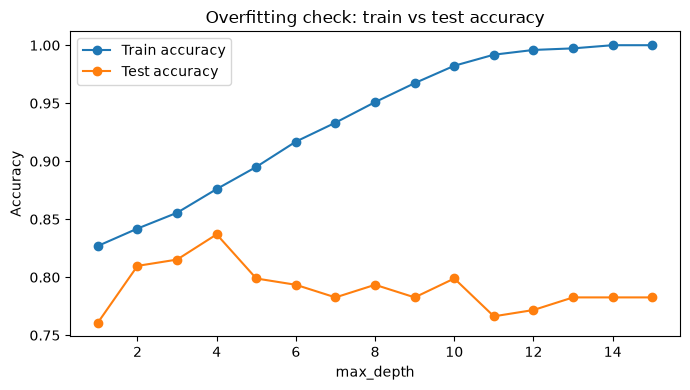

In [6]:
# ----------------------------------------------------------------------
# 4. FIND A GOOD max_depth (train vs test accuracy curve)
# ----------------------------------------------------------------------

depths = range(1, 16)
train_acc, test_acc = [], []

for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train))
    test_acc.append(t.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, marker='o', label="Train accuracy")
plt.plot(depths, test_acc, marker='o', label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Overfitting check: train vs test accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("depth_vs_accuracy.png")
plt.show()

In [7]:
tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,                 # at most 3 questions deep
    min_samples_leaf=10,         # every leaf must contain at least 10 patients
    random_state=42
)
tree.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current n


=== PRUNED TREE (max_depth=3) ===
Confusion matrix:
 [[68 14]
 [20 82]]
TN=68  FP=14  FN=20  TP=82
Train acc  : 0.8556
Test acc   : 0.8152
Precision  : 0.8542
Recall     : 0.8039
F1-score   : 0.8283

               precision    recall  f1-score   support

  No disease       0.77      0.83      0.80        82
     Disease       0.85      0.80      0.83       102

    accuracy                           0.82       184
   macro avg       0.81      0.82      0.81       184
weighted avg       0.82      0.82      0.82       184



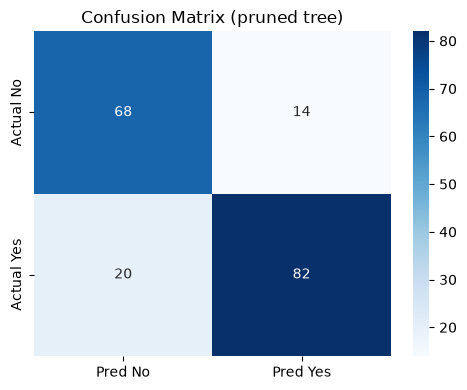

In [9]:
y_pred = tree.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("\n=== PRUNED TREE (max_depth=3) ===")
print("Confusion matrix:\n", cm)
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print("Train acc  :", round(tree.score(X_train, y_train), 4))
print("Test acc   :", round(accuracy_score(y_test, y_pred), 4))
print("Precision  :", round(precision_score(y_test, y_pred), 4))
print("Recall     :", round(recall_score(y_test, y_pred), 4))
print("F1-score   :", round(f1_score(y_test, y_pred), 4))
print("\n", classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred No", "Pred Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.title("Confusion Matrix (pruned tree)")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

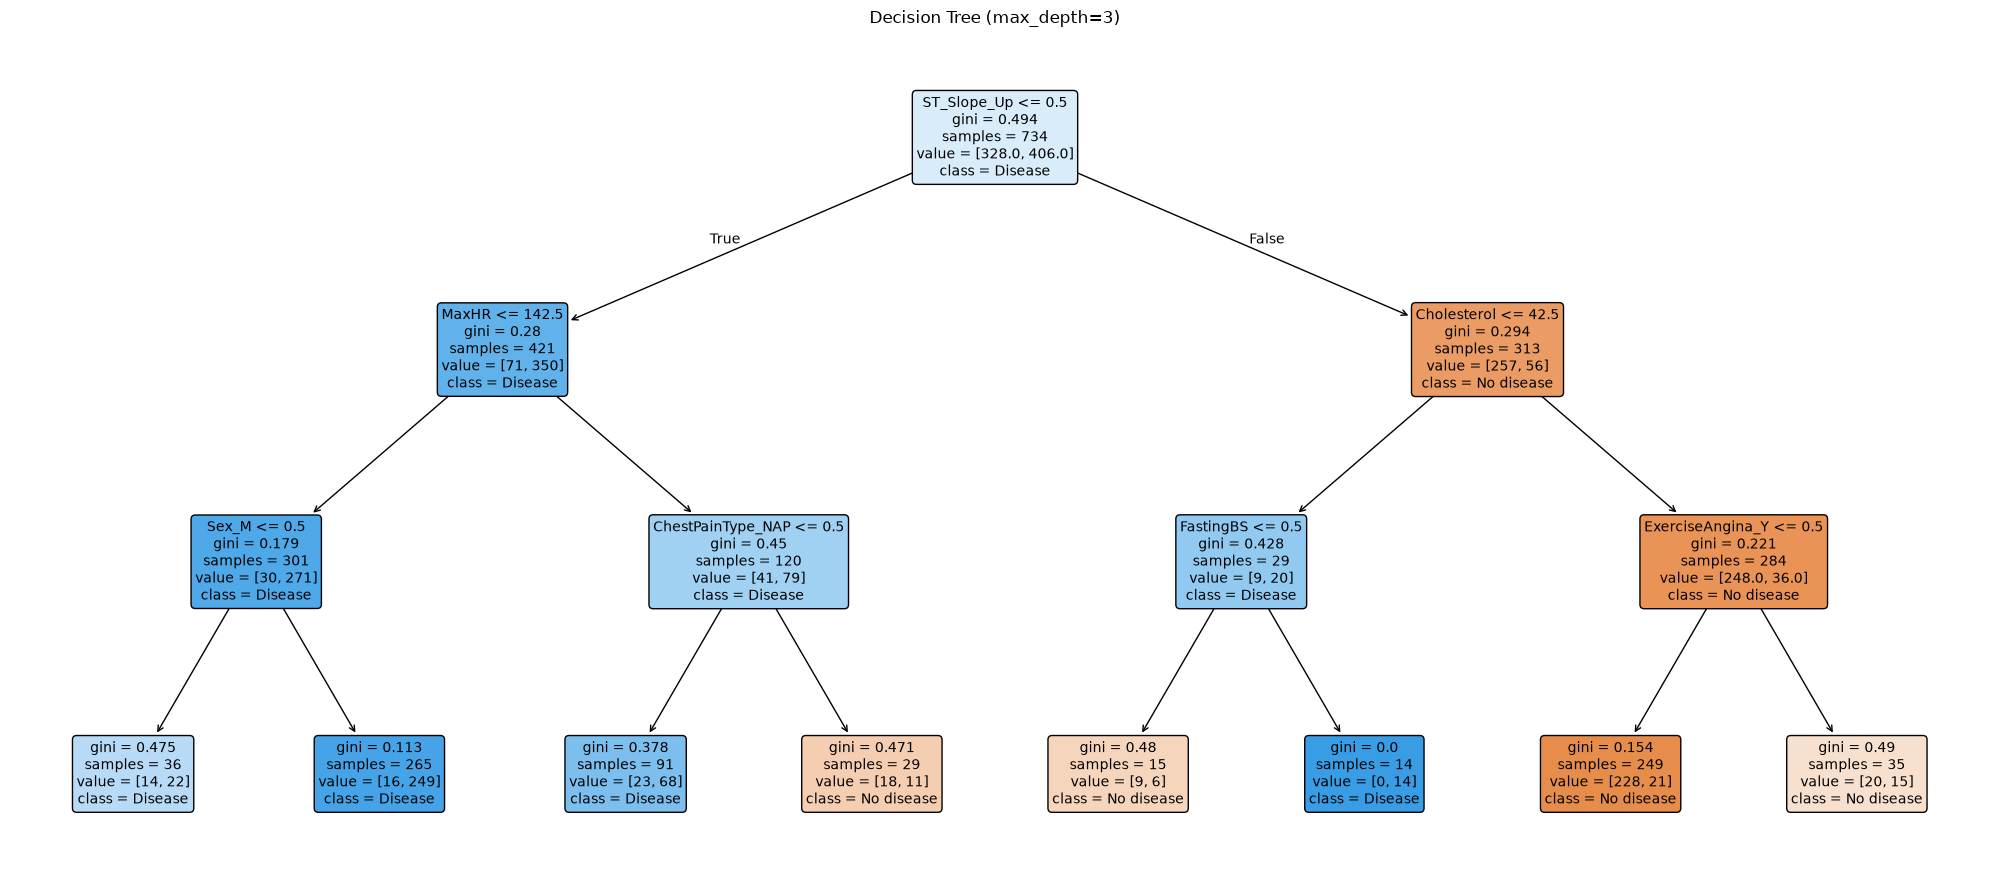

In [10]:
# ----------------------------------------------------------------------
# 7. VISUALIZE THE TREE
# ----------------------------------------------------------------------

plt.figure(figsize=(20, 9))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["No disease", "Disease"],
    filled=True,                     # colour by majority class
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree (max_depth=3)")
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=150)
plt.show()



Feature importances:
 ST_Slope_Up          0.746126
Cholesterol          0.081400
MaxHR                0.049056
ExerciseAngina_Y     0.035502
Sex_M                0.033395
ChestPainType_NAP    0.029068
FastingBS            0.025452
dtype: float64


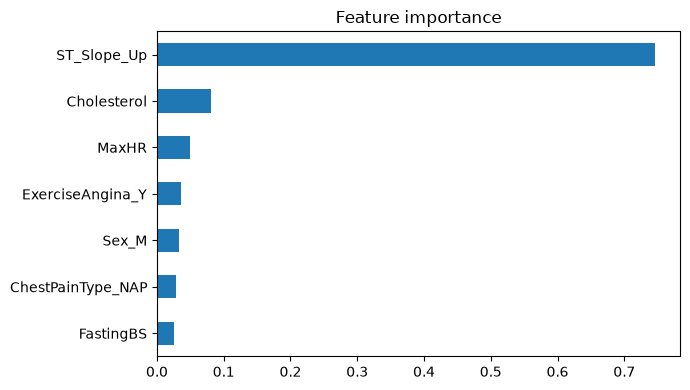

In [11]:
# ----------------------------------------------------------------------
# 8. FEATURE IMPORTANCE
# ----------------------------------------------------------------------

imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nFeature importances:\n", imp[imp > 0])

plt.figure(figsize=(7, 4))
imp[imp > 0].sort_values().plot(kind="barh")
plt.title("Feature importance")
plt.tight_layout()
plt.show()